Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 1, 861, 16)     │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 1, 430, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1, 430, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 1, 429, 32)     │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 1, 214, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1, 214, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 1, 213, 64)     │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 1, 106, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1, 106, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 1, 105, 128)    │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 1, 52, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1, 52, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,776 (85.06 KB)

 Trainable params: 21,776 (85.06 KB)

 Non-trainable params: 0 (0.00 B)

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
[0]	validation_0-mlogloss:1.67907
[1]	validation_0-mlogloss:1.58279
[2]	validation_0-mlogloss:1.49596
[3]	validation_0-mlogloss:1.41751
[4]	validation_0-mlogloss:1.34704
[5]	validation_0-mlogloss:1.28480
[6]	validation_0-mlogloss:1.22742
[7]	validation_0-mlogloss:1.17384
[8]	validation_0-mlogloss:1.12303
[9]	validation_0-mlogloss:1.07949
[10]	validation_0-mlogloss:1.03953
[11]	validation_0-mlogloss:1.00148
[12]	validation_0-mlogloss:0.96556
[13]	validation_0-mlogloss:0.93227
[14]	validation_0-mlogloss:0.90152
[15]	validation_0-mlogloss:0.87119
[16]	validation_0-mlogloss:0.84272
[17]	validation_0-mlogloss:0.81734
[18]	validation_0-mlogloss:0.79366
[19]	validation_0-mlogloss:0.77321
[20]	validation_0-mlogloss:0.75244
[21]	validation_0-mlogloss:0.73210
[22]	validation_0-mlogloss:0.71306
[23]	validation_0-mlogloss:0.69369
[24]	validation_0-mlogloss:0.67722
[25]	validation_0-mlogloss:0.66081
[26]	validation_0-mlogl

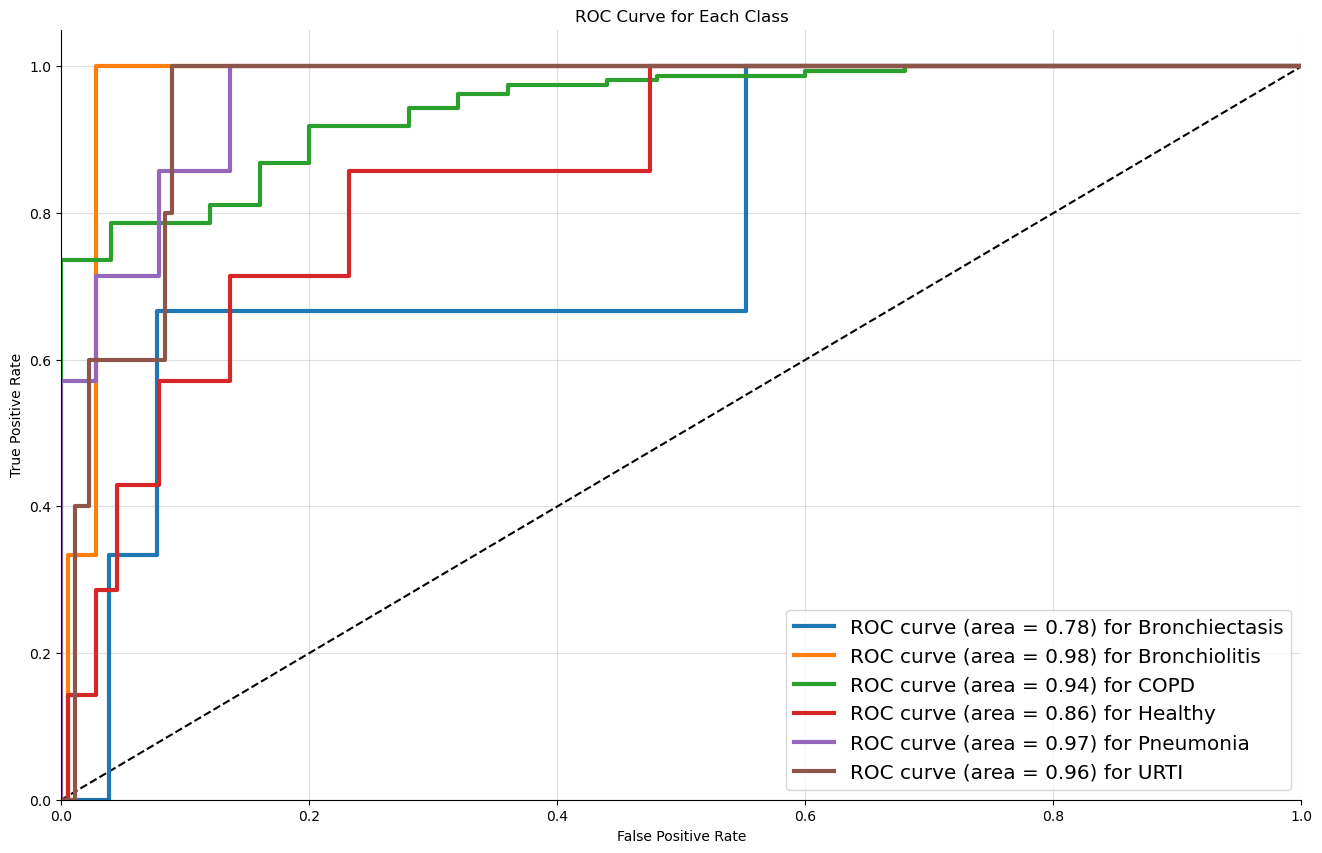

In [1]:
import xgboost as xgb
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import numpy as np
from datetime import datetime
from os import listdir
from os.path import isfile, join
import librosa
import numpy as np
import pandas as pd
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Conv2D, MaxPooling2D, GlobalAveragePooling2D, Input
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns

# File paths and loading data
mypath = "E:\\FFF\\respiratory-sound-database\\Respiratory_Sound_Database\\Respiratory_Sound_Database\\audio_and_txt_files\\"
filenames = [f for f in listdir(mypath) if (isfile(join(mypath, f)) and f.endswith('.wav'))]
p_id_in_file = [int(name[:3]) for name in filenames]
p_id_in_file = np.array(p_id_in_file)
max_pad_len = 862

# Feature extraction function (using Spectral Bandwidth instead of MFCC)
def extract_features(file_name):
    try:
        audio, sample_rate = librosa.load(file_name, res_type='kaiser_fast', duration=20)
        # Extract Spectral Bandwidth
        spectral_bandwidth = librosa.feature.spectral_bandwidth(y=audio, sr=sample_rate)
        pad_width = max_pad_len - spectral_bandwidth.shape[1]
        spectral_bandwidth = np.pad(spectral_bandwidth, pad_width=((0, 0), (0, pad_width)), mode='constant')
    except Exception as e:
        print(f"Error encountered while parsing file: {file_name}")
        print(f"Exception: {e}")
        return None 
    return spectral_bandwidth

filepaths = [join(mypath, f) for f in filenames]
p_diag = pd.read_csv("E:\\FFF\\respiratory-sound-database\\Respiratory_Sound_Database\\Respiratory_Sound_Database/patient_diagnosis.csv", header=None)
labels = np.array([p_diag[p_diag[0] == x][1].values[0] for x in p_id_in_file])
features = [extract_features(file_name) for file_name in filepaths]
features = np.array(features)

# Removing specific labels and converting labels
features1 = np.delete(features, np.where((labels == 'Asthma') | (labels == 'LRTI'))[0], axis=0)
labels1 = np.delete(labels, np.where((labels == 'Asthma') | (labels == 'LRTI'))[0], axis=0)

# One-hot encode labels
le = LabelEncoder()
i_labels = le.fit_transform(labels1)
oh_labels = to_categorical(i_labels)

# Reshape features for CNN
features1 = np.reshape(features1, (*features1.shape, 1))

# Train-test split
x_train, x_test, y_train, y_test = train_test_split(features1, oh_labels, stratify=oh_labels, test_size=0.2, random_state=42)

# Define CNN model for feature extraction
num_rows = 1  # Spectral Bandwidth has 1 row
num_columns = 862
num_channels = 1
filter_size = (1, 2)  # Smaller kernel size

cnn_model = Sequential()
cnn_model.add(Input(shape=(num_rows, num_columns, num_channels)))
cnn_model.add(Conv2D(filters=16, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling2D(pool_size=(1, 2)))  # Smaller pooling size
cnn_model.add(Dropout(0.2))
cnn_model.add(Conv2D(filters=32, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling2D(pool_size=(1, 2)))  # Smaller pooling size
cnn_model.add(Dropout(0.2))
cnn_model.add(Conv2D(filters=64, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling2D(pool_size=(1, 2)))  # Smaller pooling size
cnn_model.add(Dropout(0.2))
cnn_model.add(Conv2D(filters=128, kernel_size=filter_size, activation='relu'))
cnn_model.add(MaxPooling2D(pool_size=(1, 2)))  # Smaller pooling size
cnn_model.add(Dropout(0.2))
cnn_model.add(GlobalAveragePooling2D())

cnn_model.compile(loss='categorical_crossentropy', metrics=['accuracy'], optimizer='adam')
cnn_model.summary()

# Extract features using CNN
x_train_features = cnn_model.predict(x_train)
x_test_features = cnn_model.predict(x_test)

# Flatten the features for XGBoost
x_train_features = x_train_features.reshape(x_train_features.shape[0], -1)
x_test_features = x_test_features.reshape(x_test_features.shape[0], -1)

# Convert one-hot labels to single integers for XGBoost
y_train = np.argmax(y_train, axis=1)
y_test = np.argmax(y_test, axis=1)

# XGBoost model with early_stopping_rounds in the constructor
xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.8,
    gamma=0.1,
    use_label_encoder=False,
    eval_metric='mlogloss',
    early_stopping_rounds=10  # Moved here from the fit method
)

# Train the XGBoost model
xgb_model.fit(
    x_train_features,
    y_train,
    eval_set=[(x_test_features, y_test)],  # Evaluation set for early stopping
    verbose=True
)

# Evaluate model
y_pred = xgb_model.predict(x_test_features)
accuracy = accuracy_score(y_test, y_pred)
print(f"XGBoost Test Accuracy: {accuracy:.4f}")

# Confusion matrix and classification report
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_, zero_division=1))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Plot ROC curves
fpr = dict()
tpr = dict()
roc_auc = dict()
y_test_onehot = to_categorical(y_test, num_classes=len(le.classes_))
y_pred_proba = xgb_model.predict_proba(x_test_features)
for i in range(len(le.classes_)):
    fpr[i], tpr[i], _ = roc_curve(y_test_onehot[:, i], y_pred_proba[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# ROC Curve Plot
fig, ax = plt.subplots(figsize=(16, 10))
ax.plot([0, 1], [0, 1], 'k--')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve for Each Class')
for i in range(len(le.classes_)):
    ax.plot(fpr[i], tpr[i], linewidth=3, label='ROC curve (area = %0.2f) for %s' % (roc_auc[i], le.classes_[i]))
ax.legend(loc="best", fontsize='x-large')
ax.grid(alpha=.4)
sns.despine()
plt.show()